# 05 · Submission — Semillerio

## Formato de submission (instrucciones del bot)
- Mensaje privado a `@competencia-uno` en Zulip
- Cuerpo: `submit NombreInterno` (sin espacios en el nombre)
- Adjuntos: archivos `.csv` **sin header**, solo `numero_de_cliente` como entero
- Entre 8.000 y 15.000 registros por archivo (solo los clientes a intervenir)
- Hasta 20 archivos por submit
- ⚠️ IDs deben ser enteros — no notación científica (4.8e+07 falla)

## Estrategia: semillerio con múltiples cortes
Entrenamos el modelo final con **4 semillas distintas** y generamos predicciones.
Para cada semilla tomamos **5 cortes** (top N clientes por probabilidad).
Total: 4 semillas × 5 cortes = **20 archivos** → un submit completo.

El bot devuelve ganancia media y desvío sobre el 25% público.
Desvío bajo = modelo estable. Ganancia alta = buen modelo.

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 5 — Submission  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install lightgbm --quiet

In [3]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions'
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B = RUTA_COMP / 'dataset_fe_v3.parquet'
CKPT_C = RUTA_COMP / 'mejores_params_optuna_v3.json'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID           = 'numero_de_cliente'
COL_PERIODO      = 'foto_mes'
TARGET_RAW       = 'clase_ternaria'
TARGET           = 'es_baja2'
MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108

GANANCIA_TP =  1_072_500
COSTO_FP    =    -27_500

# ─── Semillerio ───────────────────────────────────────────────────────────────
SEMILLAS = [42, 123, 777, 2024]   # 4 semillas

# Cortes: top N clientes por probabilidad (de mayor a menor)
# Rango válido según el bot: 8.000 a 15.000
# Elegimos 5 puntos distribuidos en ese rango
CORTES_N = [9_250, 9_500, 9_750, 10_000, 10_250]

print(f'Semillas: {SEMILLAS}')
print(f'Cortes (top N): {CORTES_N}')
print(f'Total archivos a generar: {len(SEMILLAS) * len(CORTES_N)} (máx 20 por submit)')
print(f'\nCheckpoints:')
print(f'  CKPT_B: {"✓" if CKPT_B.exists() else "✗"} {CKPT_B.name}')
print(f'  CKPT_C: {"✓" if CKPT_C.exists() else "✗"} {CKPT_C.name}')

Semillas: [42, 123, 777, 2024]
Cortes (top N): [9250, 9500, 9750, 10000, 10250]
Total archivos a generar: 20 (máx 20 por submit)

Checkpoints:
  CKPT_B: ✓ dataset_fe_v3.parquet
  CKPT_C: ✓ mejores_params_optuna_v3.json


## 1 · Cargar datos y parámetros

In [4]:
# Dataset con FE
print('Cargando dataset_fe_v3.parquet...')
df = pd.read_parquet(CKPT_B)
mem = df.memory_usage(deep=True).sum() / 1024**2
print(f'  {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem:.1f} MB')

# Parámetros Optuna
with open(CKPT_C) as f:
    params_guardados = json.load(f)

PARAMS_BASE = {k: v for k, v in params_guardados.items()
               if k not in {'ganancia_optuna_fold4', 'auc_fold4', 'n_trials', 'fecha'}}
PARAMS_BASE.update({
    'objective': 'binary', 'metric': 'binary_logloss',
    'boosting_type': 'gbdt', 'verbosity': -1, 'n_jobs': -1,
})
# Sacamos random_state — lo vamos a fijar por semilla en cada iteración
PARAMS_BASE.pop('random_state', None)

print(f'\nParámetros Optuna cargados:')
for k, v in PARAMS_BASE.items():
    if k not in {'objective', 'metric', 'boosting_type', 'verbosity', 'n_jobs'}:
        print(f'  {k}: {v}')

Cargando dataset_fe_v3.parquet...
  983,061 filas × 327 columnas — 1041.6 MB

Parámetros Optuna cargados:
  num_leaves: 24
  max_depth: 5
  learning_rate: 0.025832729613126503
  n_estimators: 950
  min_child_samples: 168
  feature_fraction: 0.6386999057405924
  bagging_fraction: 0.4270280340719993
  bagging_freq: 4
  reg_alpha: 0.0014826385435596646
  reg_lambda: 0.5480606961681793
  scale_pos_weight: 223.3988606436954


In [5]:
# Features y splits
EXCLUIR = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Train: todos los meses con target real
mask_train = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
X_train = df.loc[mask_train, FEATURE_COLS]
y_train = df.loc[mask_train, TARGET].astype(int)

# Datos a predecir (202108)
mask_pred  = df[COL_PERIODO] == MES_PREDECIR
X_pred     = df.loc[mask_pred, FEATURE_COLS]
ids_pred   = df.loc[mask_pred, COL_ID].values

print(f'Train: {len(y_train):,} filas | baja2={y_train.sum():,} ({y_train.mean()*100:.3f}%)')
print(f'A predecir (202108): {len(X_pred):,} clientes')
print(f'Features: {len(FEATURE_COLS)}')

Train: 650,066 filas | baja2=4,067 (0.626%)
A predecir (202108): 164,647 clientes
Features: 323


## 2 · Semillerio — entrenamiento con múltiples semillas

Para cada semilla entrenamos el modelo completo y guardamos las probabilidades.
Después promediamos las probabilidades de las 4 semillas para obtener el score final estabilizado.

In [6]:
probs_por_semilla = []

for semilla in SEMILLAS:
    print(f'Entrenando semilla {semilla}...', end=' ')
    params = {**PARAMS_BASE, 'random_state': semilla}
    modelo = lgb.LGBMClassifier(**params)
    modelo.fit(X_train, y_train, callbacks=[lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(X_pred)[:, 1]
    probs_por_semilla.append(prob)
    print(f'✓ (prob media: {prob.mean():.5f}, max: {prob.max():.4f})')
    del modelo; gc.collect()

# Promedio de probabilidades entre semillas (ensemble simple)
probs_matrix  = np.vstack(probs_por_semilla)   # shape: (4, n_clientes)
prob_promedio = probs_matrix.mean(axis=0)
prob_std      = probs_matrix.std(axis=0)

print(f'\n✓ Semillerio completo')
print(f'  Prob promedio — media: {prob_promedio.mean():.5f} | max: {prob_promedio.max():.4f}')
print(f'  Std entre semillas — media: {prob_std.mean():.5f} | max: {prob_std.max():.4f}')

Entrenando semilla 42... ✓ (prob media: 0.13659, max: 0.9902)
Entrenando semilla 123... ✓ (prob media: 0.13454, max: 0.9940)
Entrenando semilla 777... ✓ (prob media: 0.13699, max: 0.9908)
Entrenando semilla 2024... ✓ (prob media: 0.13658, max: 0.9933)

✓ Semillerio completo
  Prob promedio — media: 0.13617 | max: 0.9889
  Std entre semillas — media: 0.03062 | max: 0.3503


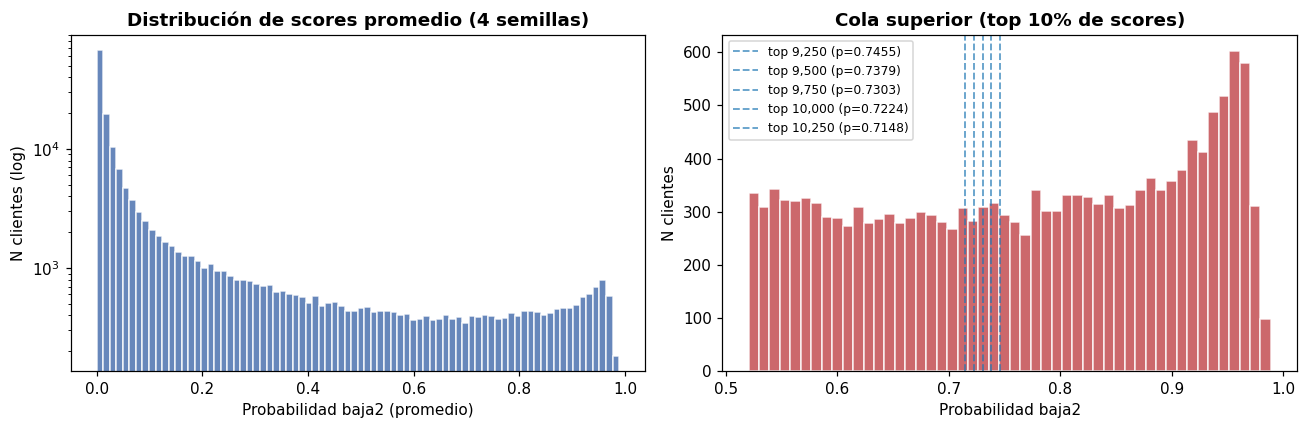


Thresholds de probabilidad para cada corte:
  Corte (top N) |    Threshold |  % del total
─────────────────────────────────────────────
          9,250 |     0.745511 |        5.62%
          9,500 |     0.737869 |        5.77%
          9,750 |     0.730279 |        5.92%
         10,000 |     0.722402 |        6.07%
         10,250 |     0.714808 |        6.23%


In [7]:
# Distribución de scores promedio
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(prob_promedio, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.set_yscale('log')
ax.set_title('Distribución de scores promedio (4 semillas)', fontweight='bold')
ax.set_xlabel('Probabilidad baja2 (promedio)')
ax.set_ylabel('N clientes (log)')

# Zoom en la cola superior (candidatos a intervenir)
ax = axes[1]
umbral_zoom = np.percentile(prob_promedio, 90)
cola = prob_promedio[prob_promedio >= umbral_zoom]
ax.hist(cola, bins=50, color='#C44E52', edgecolor='white', alpha=0.85)
ax.set_title('Cola superior (top 10% de scores)', fontweight='bold')
ax.set_xlabel('Probabilidad baja2')
ax.set_ylabel('N clientes')

# Marcamos los cortes
n_total = len(prob_promedio)
for n_corte in CORTES_N:
    thresh_corte = np.sort(prob_promedio)[::-1][n_corte - 1]
    if thresh_corte >= umbral_zoom:
        ax.axvline(thresh_corte, ls='--', lw=1.2, alpha=0.7,
                   label=f'top {n_corte:,} (p={thresh_corte:.4f})')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Tabla de thresholds por corte
print('\nThresholds de probabilidad para cada corte:')
print(f'{"Corte (top N)":>15} | {"Threshold":>12} | {"% del total":>12}')
print('─' * 45)
for n_corte in CORTES_N:
    t = float(np.sort(prob_promedio)[::-1][n_corte - 1])
    print(f'{n_corte:>15,} | {t:>12.6f} | {n_corte/n_total*100:>11.2f}%')

## 3 · Generación de archivos de submission

Para cada combinación (semilla × corte) generamos un archivo `.csv` con:
- Solo los `numero_de_cliente` de los clientes a intervenir
- **Sin header**
- IDs como enteros (sin notación científica)
- Nombre de archivo único

In [8]:
# Timestamp para identificar este lote de submissions
TS = datetime.now().strftime('%m%d_%H%M')

archivos_generados = []

print(f'Generando archivos en: {RUTA_SUBS}')
print()

for i_semilla, semilla in enumerate(SEMILLAS):
    prob_semilla = probs_por_semilla[i_semilla]

    for n_corte in CORTES_N:
        # Threshold: el score del cliente en la posición N (ordenado desc)
        threshold = float(np.sort(prob_semilla)[::-1][n_corte - 1])

        # Clientes a intervenir: los que tienen prob >= threshold
        # Si hay empates exactos podemos tener más de N — tomamos exactamente los top N
        ranking = np.argsort(prob_semilla)[::-1][:n_corte]
        ids_intervenir = ids_pred[ranking]

        # Verificación: IDs como enteros, no notación científica
        ids_int = ids_intervenir.astype(int)

        # Nombre del archivo: sem{semilla}_top{corte}_{timestamp}
        nombre = f'sem{semilla}_top{n_corte}_{TS}'
        ruta_archivo = RUTA_SUBS / f'{nombre}.csv'

        # Guardar SIN header, solo los IDs
        pd.Series(ids_int).to_csv(ruta_archivo, index=False, header=False)

        archivos_generados.append({
            'nombre': nombre,
            'archivo': ruta_archivo.name,
            'semilla': semilla,
            'n_corte': n_corte,
            'threshold': round(threshold, 6),
            'n_clientes': len(ids_int),
        })

        print(f'  ✓ {nombre}.csv — {len(ids_int):,} clientes (thresh={threshold:.5f})')

print(f'\nTotal archivos generados: {len(archivos_generados)}')

Generando archivos en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions

  ✓ sem42_top9250_1006_0207.csv — 9,250 clientes (thresh=0.76782)
  ✓ sem42_top9500_1006_0207.csv — 9,500 clientes (thresh=0.76102)
  ✓ sem42_top9750_1006_0207.csv — 9,750 clientes (thresh=0.75448)
  ✓ sem42_top10000_1006_0207.csv — 10,000 clientes (thresh=0.74760)
  ✓ sem42_top10250_1006_0207.csv — 10,250 clientes (thresh=0.74078)
  ✓ sem123_top9250_1006_0207.csv — 9,250 clientes (thresh=0.75831)
  ✓ sem123_top9500_1006_0207.csv — 9,500 clientes (thresh=0.75078)
  ✓ sem123_top9750_1006_0207.csv — 9,750 clientes (thresh=0.74273)
  ✓ sem123_top10000_1006_0207.csv — 10,000 clientes (thresh=0.73596)
  ✓ sem123_top10250_1006_0207.csv — 10,250 clientes (thresh=0.72961)
  ✓ sem777_top9250_1006_0207.csv — 9,250 clientes (thresh=0.76861)
  ✓ sem777_top9500_1006_0207.csv — 9,500 clientes (thresh=0.76166)
  ✓ sem777_top9750_1006_0207.csv — 9,750 clientes (thresh=0.75389)
  ✓ sem777_top10000_10

In [9]:
# Resumen de archivos generados
df_archivos = pd.DataFrame(archivos_generados)
print('Resumen de archivos por semilla y corte:')
print(df_archivos.pivot_table(
    index='semilla', columns='n_corte',
    values='n_clientes', aggfunc='first'
).to_string())

# Guardar el log de archivos generados
log_path = RUTA_SUBS / f'log_submissions_{TS}.csv'
df_archivos.to_csv(log_path, index=False)
print(f'\n✓ Log guardado: {log_path.name}')

Resumen de archivos por semilla y corte:
n_corte  9250   9500   9750   10000  10250
semilla                                   
42        9250   9500   9750  10000  10250
123       9250   9500   9750  10000  10250
777       9250   9500   9750  10000  10250
2024      9250   9500   9750  10000  10250

✓ Log guardado: log_submissions_1006_0207.csv


In [10]:
# Verificación de formato — chequeamos un archivo para asegurarnos
archivo_muestra = archivos_generados[0]
ruta_muestra = RUTA_SUBS / archivo_muestra['archivo']

with open(ruta_muestra, 'r') as f:
    primeras_lineas = [f.readline().strip() for _ in range(7)]

print(f'Verificación de formato: {archivo_muestra["archivo"]}')
print(f'Primeras 7 líneas:')
for linea in primeras_lineas:
    print(f'  {linea}')

# Chequeamos que no haya notación científica
df_check = pd.read_csv(ruta_muestra, header=None, names=['id'])
tiene_punto = df_check['id'].astype(str).str.contains('\.').any()
tiene_e     = df_check['id'].astype(str).str.lower().str.contains('e').any()
print(f'\nVerificaciones:')
print(f'  Sin decimales: {"✓" if not tiene_punto else "✗ PROBLEMA"}')
print(f'  Sin notación científica: {"✓" if not tiene_e else "✗ PROBLEMA"}')
print(f'  N filas: {len(df_check):,} (esperado: {archivo_muestra["n_corte"]:,})')

Verificación de formato: sem42_top9250_1006_0207.csv
Primeras 7 líneas:
  34416958
  39211311
  71821194
  53340120
  55516699
  52733895
  45696840

Verificaciones:
  Sin decimales: ✓
  Sin notación científica: ✓
  N filas: 9,250 (esperado: 9,250)


## 5 · Instrucciones para el submit en Zulip

In [11]:
nombre_submit = f'v3_semillerio_{TS}'   # cambiar si ya usaste este nombre

print('=' * 60)
print('INSTRUCCIONES PARA SUBMIT EN ZULIP')
print('=' * 60)
print()
print('1. Ir a Zulip y enviar mensaje privado a @competencia-uno')
print()
print('2. Cuerpo del mensaje:')
print(f'   submit {nombre_submit}')
print()
print('3. Adjuntar los siguientes archivos (máx 20):')
print('   Recomendación: los 20 del semillerio (4 semillas × 5 cortes)')
print()
for rec in archivos_generados:
    print(f'   📎 {rec["archivo"]}')
print()
print('4. El bot responde con:')
print('   - Public gain mean (millones $ARS, sobre 25% del dataset)')
print('   - Public gain std dev')
print()
print('5. El submit FINAL válido es el ÚLTIMO antes del 11/10 23:59:59')
print('   Antes de esa fecha, subir el elegido nuevamente como último submit.')
print()
print('─' * 60)
print('ARCHIVOS EN DRIVE:')
print(f'  {RUTA_SUBS}')
print(f'  Total archivos: {len(list(RUTA_SUBS.glob("*.csv")))}')

INSTRUCCIONES PARA SUBMIT EN ZULIP

1. Ir a Zulip y enviar mensaje privado a @competencia-uno

2. Cuerpo del mensaje:
   submit v3_semillerio_1006_0207

3. Adjuntar los siguientes archivos (máx 20):
   Recomendación: los 20 del semillerio (4 semillas × 5 cortes)

   📎 sem42_top9250_1006_0207.csv
   📎 sem42_top9500_1006_0207.csv
   📎 sem42_top9750_1006_0207.csv
   📎 sem42_top10000_1006_0207.csv
   📎 sem42_top10250_1006_0207.csv
   📎 sem123_top9250_1006_0207.csv
   📎 sem123_top9500_1006_0207.csv
   📎 sem123_top9750_1006_0207.csv
   📎 sem123_top10000_1006_0207.csv
   📎 sem123_top10250_1006_0207.csv
   📎 sem777_top9250_1006_0207.csv
   📎 sem777_top9500_1006_0207.csv
   📎 sem777_top9750_1006_0207.csv
   📎 sem777_top10000_1006_0207.csv
   📎 sem777_top10250_1006_0207.csv
   📎 sem2024_top9250_1006_0207.csv
   📎 sem2024_top9500_1006_0207.csv
   📎 sem2024_top9750_1006_0207.csv
   📎 sem2024_top10000_1006_0207.csv
   📎 sem2024_top10250_1006_0207.csv

4. El bot responde con:
   - Public gain mean (

## 6 · Análisis de variabilidad entre semillas

¿Qué tan estables son las predicciones entre semillas? Un desvío alto significa que el modelo es inestable — señal de overfitting o features ruidosas.

In [12]:
# Acuerdo entre semillas para los top clientes
# Para cada corte: ¿cuántos clientes aparecen en TODAS las semillas?
print('Estabilidad del semillerio por corte:')
print(f'{"Corte":>8} | {"En 4/4 semillas":>15} | {"En 3/4 semillas":>15} | {"Solo en 1":>12}')
print('─' * 58)

for n_corte in CORTES_N:
    sets_por_semilla = []
    for prob_s in probs_por_semilla:
        top_idx = set(np.argsort(prob_s)[::-1][:n_corte])
        sets_por_semilla.append(top_idx)

    # Intersección: en todas las semillas
    en_todas = len(sets_por_semilla[0].intersection(*sets_por_semilla[1:]))
    # En al menos 3 de 4
    conteo = np.zeros(len(ids_pred), dtype=int)
    for s in sets_por_semilla:
        for idx in s:
            conteo[idx] += 1
    en_3_de_4 = (conteo >= 3).sum()
    solo_en_1 = (conteo == 1).sum()

    print(f'{n_corte:>8,} | {en_todas:>10,} ({en_todas/n_corte*100:.0f}%) | '
          f'{en_3_de_4:>10,} ({en_3_de_4/n_corte*100:.0f}%) | '
          f'{solo_en_1:>8,}')

Estabilidad del semillerio por corte:
   Corte | En 4/4 semillas | En 3/4 semillas |    Solo en 1
──────────────────────────────────────────────────────────
   9,250 |      6,821 (74%) |      8,312 (90%) |    2,351
   9,500 |      7,005 (74%) |      8,544 (90%) |    2,395
   9,750 |      7,195 (74%) |      8,765 (90%) |    2,472
  10,000 |      7,390 (74%) |      8,984 (90%) |    2,504
  10,250 |      7,577 (74%) |      9,213 (90%) |    2,556


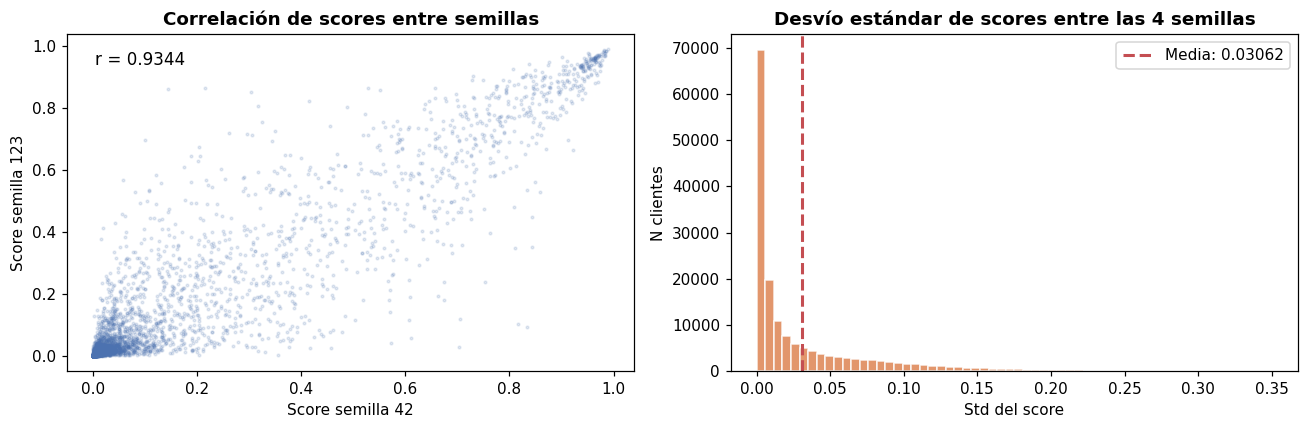

Correlación promedio entre pares de semillas:
  semilla 42 vs 123: r = 0.9344
  semilla 42 vs 777: r = 0.9377
  semilla 42 vs 2024: r = 0.9284
  semilla 123 vs 777: r = 0.9411
  semilla 123 vs 2024: r = 0.9314
  semilla 777 vs 2024: r = 0.9353


In [13]:
# Correlación de scores entre semillas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Scatter: semilla 1 vs semilla 2 (muestra aleatoria para no tardar)
ax = axes[0]
idx_muestra = np.random.choice(len(prob_promedio), size=5000, replace=False)
ax.scatter(probs_por_semilla[0][idx_muestra],
           probs_por_semilla[1][idx_muestra],
           alpha=0.15, s=3, color='#4C72B0')
ax.set_xlabel(f'Score semilla {SEMILLAS[0]}')
ax.set_ylabel(f'Score semilla {SEMILLAS[1]}')
ax.set_title('Correlación de scores entre semillas', fontweight='bold')
corr = np.corrcoef(probs_por_semilla[0], probs_por_semilla[1])[0, 1]
ax.text(0.05, 0.95, f'r = {corr:.4f}', transform=ax.transAxes,
        fontsize=11, va='top')

# Desvío estándar por cliente (entre semillas)
ax = axes[1]
ax.hist(prob_std, bins=60, color='#DD8452', edgecolor='white', alpha=0.85)
ax.set_title('Desvío estándar de scores entre las 4 semillas', fontweight='bold')
ax.set_xlabel('Std del score')
ax.set_ylabel('N clientes')
ax.axvline(prob_std.mean(), color='#C44E52', ls='--', lw=2,
           label=f'Media: {prob_std.mean():.5f}')
ax.legend()

plt.tight_layout()
plt.show()

print(f'Correlación promedio entre pares de semillas:')
for i in range(len(SEMILLAS)):
    for j in range(i+1, len(SEMILLAS)):
        r = np.corrcoef(probs_por_semilla[i], probs_por_semilla[j])[0, 1]
        print(f'  semilla {SEMILLAS[i]} vs {SEMILLAS[j]}: r = {r:.4f}')

In [14]:
# Resumen final
print('=' * 60)
print('RESUMEN SUBMISSION')
print('=' * 60)
print(f'Modelo:    LightGBM v3 + Optuna')
print(f'Semillas:  {SEMILLAS}')
print(f'Cortes:    {CORTES_N}')
print(f'Archivos:  {len(archivos_generados)} semillerio + {len(archivos_ensemble)} ensemble')
print(f'Carpeta:   {RUTA_SUBS}')
print(f'Submit ID: {nombre_submit}')
print()
print('Próximos pasos:')
print('  1. Subir los 20 archivos del semillerio a Zulip')
print('  2. Ver la ganancia media y std que devuelve el bot')
print('  3. Anotar los resultados para comparar con la próxima versión')
print('  4. Si el std es alto → el modelo es inestable → revisar features')
print('  5. Deadline: 11/10/2026 23:59:59')

gc.collect()
print('\n✓ Notebook completada.')

RESUMEN SUBMISSION
Modelo:    LightGBM v3 + Optuna
Semillas:  [42, 123, 777, 2024]
Cortes:    [9250, 9500, 9750, 10000, 10250]


NameError: name 'archivos_ensemble' is not defined